In [1]:
import os

# Creazione del file .env per le configurazioni di Ollama
env_content = """
OLLAMA_MODEL="llama3"
OLLAMA_EMBED_MODEL="nomic-embed-text"
OLLAMA_BASE_URL="http://localhost:11434"
"""

with open(".env", "w") as f:
    f.write(env_content.strip())

print("File .env creato con successo!")

File .env creato con successo!


## Cella 3: Funzioni di Configurazione (LLM ed Embeddings)

In [2]:
from dotenv import load_dotenv
from langchain_ollama import ChatOllama, OllamaEmbeddings

# Carichiamo le variabili dal file .env appena creato
load_dotenv()

MODEL = os.getenv("OLLAMA_MODEL")
EMBED_MODEL = os.getenv("OLLAMA_EMBED_MODEL")
BASE_URL = os.getenv("OLLAMA_BASE_URL", "http://localhost:11434")

def get_llm(temperature: float = 0) -> ChatOllama:
    if not MODEL:
        raise RuntimeError("Imposta la variabile OLLAMA_MODEL nel file .env")
    return ChatOllama(model=MODEL, temperature=temperature, base_url=BASE_URL)

def get_embeddings() -> OllamaEmbeddings:
    if not EMBED_MODEL:
        raise RuntimeError("Imposta la variabile OLLAMA_EMBED_MODEL nel file .env")
    return OllamaEmbeddings(model=EMBED_MODEL, base_url=BASE_URL)

print("Inizializzazione configurazione completata!")

Inizializzazione configurazione completata!


## Cella 4: Definizione dello State

In [3]:
from typing import TypedDict, List, Annotated
import operator
from langchain_core.messages import BaseMessage

class State(TypedDict):
    domanda: str
    risposta: str
    passaggi: int
    messages: Annotated[List[BaseMessage], operator.add]

## Cella 5: Definizione dei Nodi

In [4]:
from langchain_core.messages import HumanMessage

# Inizializziamo il modello LLM
llm = get_llm(temperature=0.2)

def nodo_saluto(state: State) -> dict:
    print(f"--> [Nodo 1] Preparazione richiesta per: '{state['domanda']}'")
    
    # Prepariamo il messaggio per la cronologia
    nuovo_messaggio = HumanMessage(content=state["domanda"])
    
    return {
        "passaggi": state.get("passaggi", 0) + 1,
        "messages": [nuovo_messaggio]
    }

def nodo_ollama(state: State) -> dict:
    print("--> [Nodo 2] Invio della richiesta ad Ollama...")
    
    # Inviamo l'intera cronologia dei messaggi a Ollama
    risposta_llm = llm.invoke(state["messages"])
    
    return {
        "risposta": risposta_llm.content,
        "messages": [risposta_llm],
        "passaggi": state["passaggi"] + 1
    }

## Cella 6: Costruzione e Compilazione del Grafo

In [5]:
from langgraph.graph import StateGraph, START, END

# 1. Inizializza il builder con lo State
builder = StateGraph(State)

# 2. Aggiungi i Nodi
builder.add_node("saluto", nodo_saluto)
builder.add_node("ollama", nodo_ollama)

# 3. Collega i nodi con gli Edges (Flusso)
builder.add_edge(START, "saluto")
builder.add_edge("saluto", "ollama")
builder.add_edge("ollama", END)

# 4. Compila il grafo
graph = builder.compile()

print("Grafo costruito e compilato con successo!")  

Grafo costruito e compilato con successo!


## Cella 7: Visualizzazione del Grafo (Tipico nei Notebook)

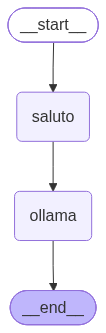

In [6]:
from IPython.display import Image, display

try:
    # Mostra la struttura visiva del grafo direttamente nel notebook
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print("Visualizzazione grafica non disponibile (richiede pygraphviz/mermaid).")